In [1]:

import pandas as pd
import numpy as np
from pathlib import Path

# Dataset file paths
DATA_DIR = Path("../data")

data_file = DATA_DIR / "diabetic_data.csv"
mapping_file = DATA_DIR / "IDS_mapping.csv"

# Check whether both files exist
print("Dataset file exists:", data_file.exists())
print("Mapping file exists:", mapping_file.exists())

# Load the dataset
df = pd.read_csv(data_file)

# Basic dataset information
print("\nDataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Display first 5 rows
display(df.head())

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Missing values
print("\nTop 15 columns with missing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# Readmission target distribution
print("\nReadmission distribution:")
print(df["readmitted"].value_counts(dropna=False))

print("\nReadmission percentage:")
print(
    (df["readmitted"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)


Dataset file exists: True
Mapping file exists: True

Dataset loaded successfully!
Number of rows: 101766
Number of columns: 50


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO



Column names:
['encounter_id', 'patient_nbr', 'race', 'gender', 'age', 'weight', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed', 'readmitted']

Top 15 columns with missing values:
max_glu_serum               96420
A1Cresult                   84748
race                            0
gender                      

In [2]:

# 1. Check duplicate records
print("Duplicate rows:", df.duplicated().sum())

# 2. Check missing-value markers
print("\nQuestion mark values in each column:")
print((df == "?").sum().sort_values(ascending=False).head(15))

# 3. Check data types
print("\nColumn data types:")
print(df.dtypes)

# 4. Check target variable
print("\nReadmission categories:")
print(df["readmitted"].value_counts())

# 5. Check target percentages
print("\nReadmission percentages:")
print(
    (df["readmitted"].value_counts(normalize=True) * 100).round(2)
)


Duplicate rows: 0

Question mark values in each column:
weight                 98569
medical_specialty      49949
payer_code             40256
race                    2273
diag_3                  1423
diag_2                   358
diag_1                    21
admission_type_id          0
patient_nbr                0
encounter_id               0
time_in_hospital           0
admission_source_id        0
num_lab_procedures         0
num_procedures             0
num_medications            0
dtype: int64

Column data types:
encounter_id                int64
patient_nbr                 int64
race                          str
gender                        str
age                           str
weight                        str
admission_type_id           int64
discharge_disposition_id    int64
admission_source_id         int64
time_in_hospital            int64
payer_code                    str
medical_specialty             str
num_lab_procedures          int64
num_procedures              int64


In [3]:

# Create a binary target for 30-day readmission
df["readmitted_30_days"] = (
    df["readmitted"] == "<30"
).astype(int)

# Check target distribution
print("30-day readmission target:")
print(df["readmitted_30_days"].value_counts())

print("\nTarget percentages:")
print(
    (df["readmitted_30_days"].value_counts(normalize=True) * 100)
    .round(2)
)

# Convert question marks into proper missing values
df_clean = df.replace("?", np.nan)

# Check missing values after conversion
print("\nTop 15 columns by missing-value percentage:")
missing_percent = (
    df_clean.isnull().mean() * 100
).sort_values(ascending=False)

print(missing_percent.head(15).round(2))

# Display target and original categories together
print("\nOriginal and new target comparison:")
print(
    pd.crosstab(
        df_clean["readmitted"],
        df_clean["readmitted_30_days"]
    )
)


30-day readmission target:
readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64

Target percentages:
readmitted_30_days
0    88.84
1    11.16
Name: proportion, dtype: float64

Top 15 columns by missing-value percentage:
weight                 96.86
max_glu_serum          94.75
A1Cresult              83.28
medical_specialty      49.08
payer_code             39.56
race                    2.23
diag_3                  1.40
diag_2                  0.35
diag_1                  0.02
patient_nbr             0.00
encounter_id            0.00
time_in_hospital        0.00
admission_source_id     0.00
num_procedures          0.00
num_lab_procedures      0.00
dtype: float64

Original and new target comparison:
readmitted_30_days      0      1
readmitted                      
<30                     0  11357
>30                 35545      0
NO                  54864      0


In [4]:

# Create a working copy
df_model = df_clean.copy()

# Remove identifiers and columns with very high missingness
columns_to_drop = [
    "encounter_id",
    "patient_nbr",
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code",
    "readmitted"
]

df_model = df_model.drop(
    columns=columns_to_drop,
    errors="ignore"
)

# Check missing values in remaining columns
print("Dataset shape after dropping columns:", df_model.shape)

print("\nRemaining missing values:")
print(
    df_model.isnull().sum()
    .sort_values(ascending=False)
    .head(15)
)

# Check target distribution
print("\nTarget distribution:")
print(df_model["readmitted_30_days"].value_counts())

# Preview the processed dataset
display(df_model.head())


Dataset shape after dropping columns: (101766, 43)

Remaining missing values:
race                        2273
diag_3                      1423
diag_2                       358
diag_1                        21
admission_type_id              0
admission_source_id            0
time_in_hospital               0
num_lab_procedures             0
discharge_disposition_id       0
gender                         0
age                            0
number_outpatient              0
num_medications                0
num_procedures                 0
number_inpatient               0
dtype: int64

Target distribution:
readmitted_30_days
0    90409
1    11357
Name: count, dtype: int64


,race,gender,age,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,num_lab_procedures,num_procedures,num_medications,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted_30_days
0,Caucasian,Female,[0-10),6,25,1,1,41,0,1,...,No,No,No,No,No,No,No,No,No,0
1,Caucasian,Female,[10-20),1,1,7,3,59,0,18,...,No,Up,No,No,No,No,No,Ch,Yes,0
2,AfricanAmerican,Female,[20-30),1,1,7,2,11,5,13,...,No,No,No,No,No,No,No,No,Yes,0
3,Caucasian,Male,[30-40),1,1,7,2,44,1,16,...,No,Up,No,No,No,No,No,Ch,Yes,0
4,Caucasian,Male,[40-50),1,1,7,1,51,0,8,...,No,Steady,No,No,No,No,No,Ch,Yes,0


In [5]:

# Make another copy for preprocessing
df_prepared = df_model.copy()

# Fill missing categorical values with the most frequent category
categorical_columns = df_prepared.select_dtypes(
    include=["object", "str"]
).columns.tolist()

for col in categorical_columns:
    df_prepared[col] = df_prepared[col].fillna("Unknown")

# Confirm that missing values are handled
print("Total missing values:", df_prepared.isnull().sum().sum())

# Separate features and target
X = df_prepared.drop(columns=["readmitted_30_days"])
y = df_prepared["readmitted_30_days"]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

# Identify categorical and numerical features
categorical_features = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))

print("\nCategorical columns:")
print(categorical_features)

print("\nNumerical columns:")
print(numerical_features)


Total missing values: 0
Feature matrix shape: (101766, 42)
Target shape: (101766,)
Categorical features: 31
Numerical features: 11

Categorical columns:
['race', 'gender', 'age', 'diag_1', 'diag_2', 'diag_3', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Numerical columns:
['admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']


In [6]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# Preprocess numerical and categorical columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

# Build the Logistic Regression model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the model
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("\nModel Evaluation")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Training records: 81412
Testing records: 20354

Model Evaluation
Accuracy: 0.6449
Precision: 0.1668
Recall: 0.546
F1-score: 0.2555
ROC-AUC: 0.6425

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.66      0.77     18083
           1       0.17      0.55      0.26      2271

    accuracy                           0.64     20354
   macro avg       0.54      0.60      0.51     20354
weighted avg       0.84      0.64      0.71     20354


Confusion Matrix:
[[11887  6196]
 [ 1031  1240]]


In [7]:

cm = confusion_matrix(y_test, y_pred)

print("True Negatives:", cm[0, 0])
print("False Positives:", cm[0, 1])
print("False Negatives:", cm[1, 0])
print("True Positives:", cm[1, 1])


True Negatives: 11887
False Positives: 6196
False Negatives: 1031
True Positives: 1240


In [8]:

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train Random Forest
rf_model.fit(X_train, y_train)

# Predictions
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Evaluation")
print("Accuracy:", round(accuracy_score(y_test, rf_pred), 4))
print("Precision:", round(precision_score(y_test, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, rf_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, rf_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))


Random Forest Evaluation
Accuracy: 0.6246
Precision: 0.1689
Recall: 0.6028
F1-score: 0.2638
ROC-AUC: 0.6606


In [9]:

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.base import clone

gb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

# Train model
gb_model.fit(X_train, y_train)

# Predictions
gb_pred = gb_model.predict(X_test)
gb_prob = gb_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Gradient Boosting Evaluation")
print("Accuracy:", round(accuracy_score(y_test, gb_pred), 4))
print("Precision:", round(precision_score(y_test, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, gb_pred, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, gb_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, gb_prob), 4))


Gradient Boosting Evaluation
Accuracy: 0.8886
Precision: 0.5484
Recall: 0.0075
F1-score: 0.0148
ROC-AUC: 0.6762


In [10]:

gb_cm = confusion_matrix(y_test, gb_pred)

print("Gradient Boosting Confusion Matrix:")
print(gb_cm)

print("\nTrue Negatives:", gb_cm[0, 0])
print("False Positives:", gb_cm[0, 1])
print("False Negatives:", gb_cm[1, 0])
print("True Positives:", gb_cm[1, 1])


Gradient Boosting Confusion Matrix:
[[18069    14]
 [ 2254    17]]

True Negatives: 18069
False Positives: 14
False Negatives: 2254
True Positives: 17


In [11]:

from sklearn.metrics import precision_score, recall_score, f1_score

# Test different probability thresholds
thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]

print("Threshold | Precision | Recall | F1-score")

for threshold in thresholds:
    pred_threshold = (gb_prob >= threshold).astype(int)

    precision = precision_score(
        y_test, pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_test, pred_threshold, zero_division=0
    )
    f1 = f1_score(
        y_test, pred_threshold, zero_division=0
    )

    print(
        f"{threshold:9.2f} | {precision:9.4f} | "
        f"{recall:6.4f} | {f1:8.4f}"
    )


Threshold | Precision | Recall | F1-score
     0.10 |    0.1617 | 0.7151 |   0.2638
     0.15 |    0.2280 | 0.3483 |   0.2756
     0.20 |    0.3004 | 0.1673 |   0.2149
     0.25 |    0.3492 | 0.0969 |   0.1517
     0.30 |    0.4198 | 0.0749 |   0.1271
     0.40 |    0.5761 | 0.0233 |   0.0449
     0.50 |    0.5484 | 0.0075 |   0.0148


In [12]:

from sklearn.model_selection import GroupShuffleSplit

# Start again from the dataset that still has patient IDs
df_group = df_clean.copy()

# Remove columns with very high missingness and identifiers
drop_cols = [
    "encounter_id",
    "weight",
    "max_glu_serum",
    "A1Cresult",
    "medical_specialty",
    "payer_code",
    "readmitted"
]

df_group = df_group.drop(columns=drop_cols, errors="ignore")

# Keep patient IDs separately for grouping; do not use them as features
groups = df_group["patient_nbr"].copy()

X_all = df_group.drop(
    columns=["patient_nbr", "readmitted_30_days"],
    errors="ignore"
)
y_all = df_group["readmitted_30_days"].astype(int)

# First split: 80% development patients, 20% test patients
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)
dev_idx, test_idx = next(
    split1.split(X_all, y_all, groups=groups)
)

X_dev = X_all.iloc[dev_idx]
y_dev = y_all.iloc[dev_idx]
groups_dev = groups.iloc[dev_idx]

X_test = X_all.iloc[test_idx]
y_test = y_all.iloc[test_idx]
groups_test = groups.iloc[test_idx]

# Second split: 75% of development for training, 25% for validation
# Overall this is approximately 60% train, 20% validation, 20% test
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.25, random_state=43
)
train_idx, val_idx = next(
    split2.split(X_dev, y_dev, groups=groups_dev)
)

X_train = X_dev.iloc[train_idx]
y_train = y_dev.iloc[train_idx]
groups_train = groups_dev.iloc[train_idx]

X_val = X_dev.iloc[val_idx]
y_val = y_dev.iloc[val_idx]
groups_val = groups_dev.iloc[val_idx]

# Verify that no patient appears in more than one split
print("Training records:", len(X_train))
print("Validation records:", len(X_val))
print("Testing records:", len(X_test))

print("\nUnique patients:")
print("Train:", groups_train.nunique())
print("Validation:", groups_val.nunique())
print("Test:", groups_test.nunique())

print("\nPatient overlap checks:")
print("Train vs Validation:", len(set(groups_train) & set(groups_val)))
print("Train vs Test:", len(set(groups_train) & set(groups_test)))
print("Validation vs Test:", len(set(groups_val) & set(groups_test)))

print("\nPositive target rate:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Validation:", round(y_val.mean() * 100, 2), "%")
print("Test:", round(y_test.mean() * 100, 2), "%")


Training records: 61215
Validation records: 20398
Testing records: 20153

Unique patients:
Train: 42910
Validation: 14304
Test: 14304

Patient overlap checks:
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

Positive target rate:
Train: 11.33 %
Validation: 11.13 %
Test: 10.67 %


In [13]:

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    accuracy_score, roc_auc_score
)
import pandas as pd
import numpy as np

# Define all three models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
}

# Use validation data to select the best F1 threshold
thresholds = np.arange(0.05, 0.51, 0.01)

trained_models = {}
validation_results = {}
final_results = []

for name, classifier in models.items():
    pipe = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("classifier", classifier)
    ])

    pipe.fit(X_train, y_train)
    trained_models[name] = pipe

    val_prob = pipe.predict_proba(X_val)[:, 1]

    threshold_scores = []
    for threshold in thresholds:
        val_pred = (val_prob >= threshold).astype(int)
        score = f1_score(y_val, val_pred, zero_division=0)
        threshold_scores.append(score)

    best_index = int(np.argmax(threshold_scores))
    best_threshold = float(thresholds[best_index])
    validation_results[name] = best_threshold

    # Final evaluation on the untouched test set
    test_prob = pipe.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)

    final_results.append({
        "Model": name,
        "Validation Threshold": round(best_threshold, 2),
        "Test Accuracy": round(accuracy_score(y_test, test_pred), 4),
        "Test Precision": round(
            precision_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test Recall": round(
            recall_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test F1": round(
            f1_score(y_test, test_pred, zero_division=0), 4
        ),
        "Test ROC-AUC": round(
            roc_auc_score(y_test, test_prob), 4
        )
    })

results_df = pd.DataFrame(final_results)

print("Selected thresholds (chosen on validation set):")
print(validation_results)

print("\nFinal test-set comparison:")
display(results_df)


Selected thresholds (chosen on validation set):
{'Logistic Regression': 0.5000000000000001, 'Random Forest': 0.5000000000000001, 'Gradient Boosting': 0.13}

Final test-set comparison:


,Model,Validation Threshold,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC
0,Logistic Regression,0.50,0.6385,0.1528,0.5253,0.2368,0.6242
1,Random Forest,0.50,0.6286,0.1575,0.5700,0.2468,0.6436
2,Gradient Boosting,0.13,0.7432,0.1882,0.4245,0.2608,0.6619


Top 15 Important Features:


,Feature,Importance
9,num__number_inpatient,0.454336
1,num__discharge_disposition_id,0.214156
8,num__number_emergency,0.029862
692,cat__diag_1_V58,0.023696
10,num__number_diagnoses,0.014448
4,num__num_lab_procedures,0.014365
3,num__time_in_hospital,0.013718
1750,cat__diag_3_581,0.008393
1481,cat__diag_3_250.6,0.008214
2175,cat__diabetesMed_No,0.007444


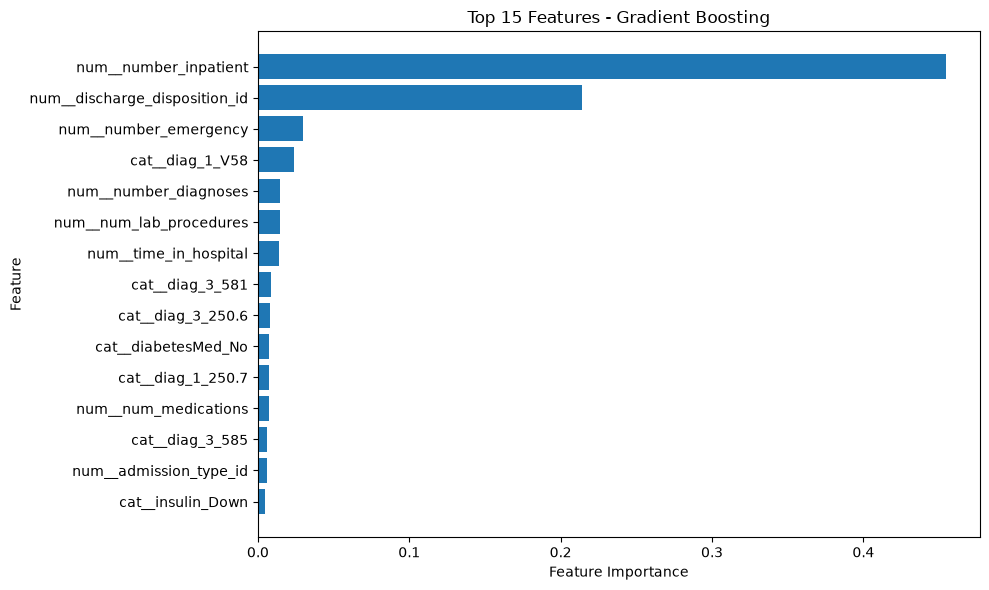

In [14]:

import pandas as pd
import matplotlib.pyplot as plt

# Get the trained Gradient Boosting model
gb_pipeline = trained_models["Gradient Boosting"]

# Get preprocessed feature names
preprocessor_fitted = gb_pipeline.named_steps["preprocessor"]

feature_names = preprocessor_fitted.get_feature_names_out()

# Get feature importance scores
importances = gb_pipeline.named_steps["classifier"].feature_importances_

# Create a sorted table
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values(by="Importance", ascending=False)

# Display top 15 features
print("Top 15 Important Features:")
display(importance_df.head(15))

# Plot top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Gradient Boosting")
plt.tight_layout()
plt.show()


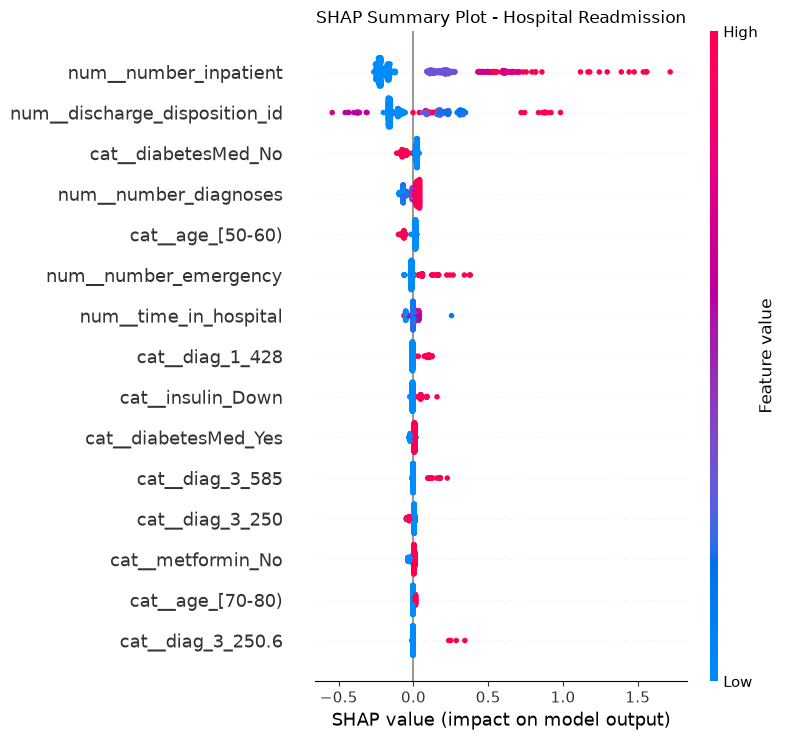

In [16]:


import numpy as np
import shap
import matplotlib.pyplot as plt
from scipy import sparse

# Get the trained Gradient Boosting pipeline
gb_pipeline = trained_models["Gradient Boosting"]

# Sample test records
X_sample = X_test.sample(
    n=min(500, len(X_test)),
    random_state=42
)

# Transform features
X_transformed = gb_pipeline.named_steps[
    "preprocessor"
].transform(X_sample)

# Convert sparse matrix to dense array if needed
if sparse.issparse(X_transformed):
    X_transformed = X_transformed.toarray()

# Ensure numeric data type
X_transformed = np.asarray(
    X_transformed, dtype=np.float64
)

# Get feature names
feature_names = gb_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Explain predictions
classifier = gb_pipeline.named_steps["classifier"]
explainer = shap.TreeExplainer(classifier)

shap_values = explainer.shap_values(X_transformed)

# Plot the SHAP summary
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=15,
    show=False
)

plt.title("SHAP Summary Plot - Hospital Readmission")
plt.tight_layout()
plt.show()


Predicted probability of 30-day readmission: 0.1178
Prediction at threshold 0.13: 0


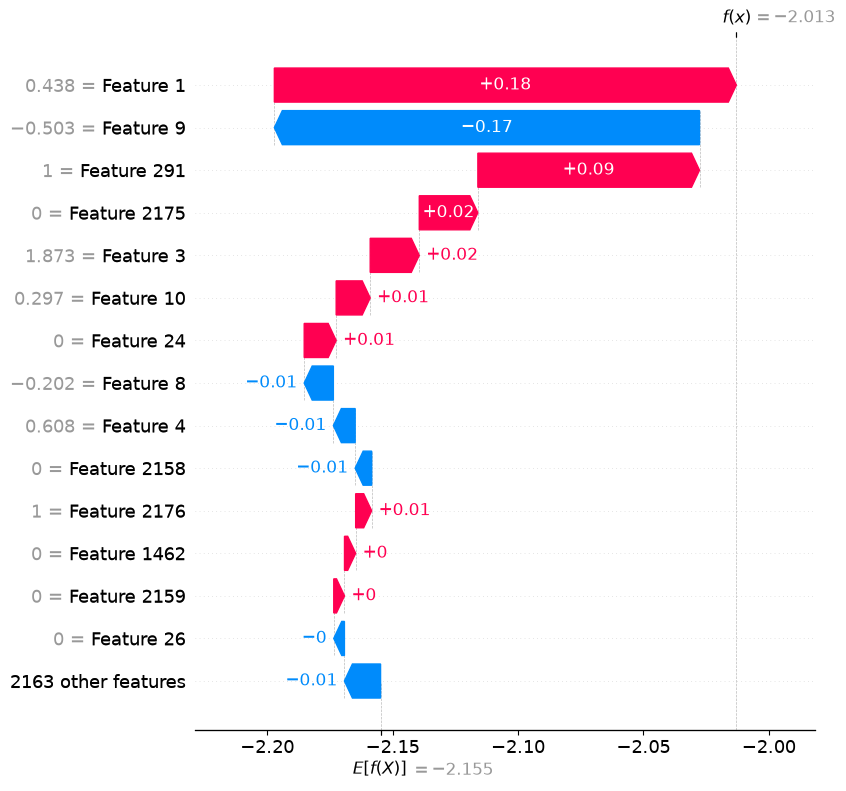

In [17]:

import shap
import numpy as np
from scipy import sparse
import matplotlib.pyplot as plt

# Use the trained Gradient Boosting model
gb_pipeline = trained_models["Gradient Boosting"]
preprocessor_fitted = gb_pipeline.named_steps["preprocessor"]
classifier = gb_pipeline.named_steps["classifier"]

# Select one record from the test set
X_one = X_test.iloc[[0]]

# Transform the record
X_one_transformed = preprocessor_fitted.transform(X_one)

if sparse.issparse(X_one_transformed):
    X_one_transformed = X_one_transformed.toarray()

X_one_transformed = np.asarray(
    X_one_transformed, dtype=np.float64
)

feature_names = preprocessor_fitted.get_feature_names_out()

# Explain this record
explainer = shap.TreeExplainer(classifier)
shap_values_one = explainer(X_one_transformed)

# Show the model's predicted probability
probability = gb_pipeline.predict_proba(X_one)[0, 1]
prediction = gb_pipeline.predict(X_one)[0]

print("Predicted probability of 30-day readmission:", round(probability, 4))
print("Prediction at threshold 0.13:", int(probability >= 0.13))

# Waterfall explanation
shap.plots.waterfall(
    shap_values_one[0],
    max_display=15
)


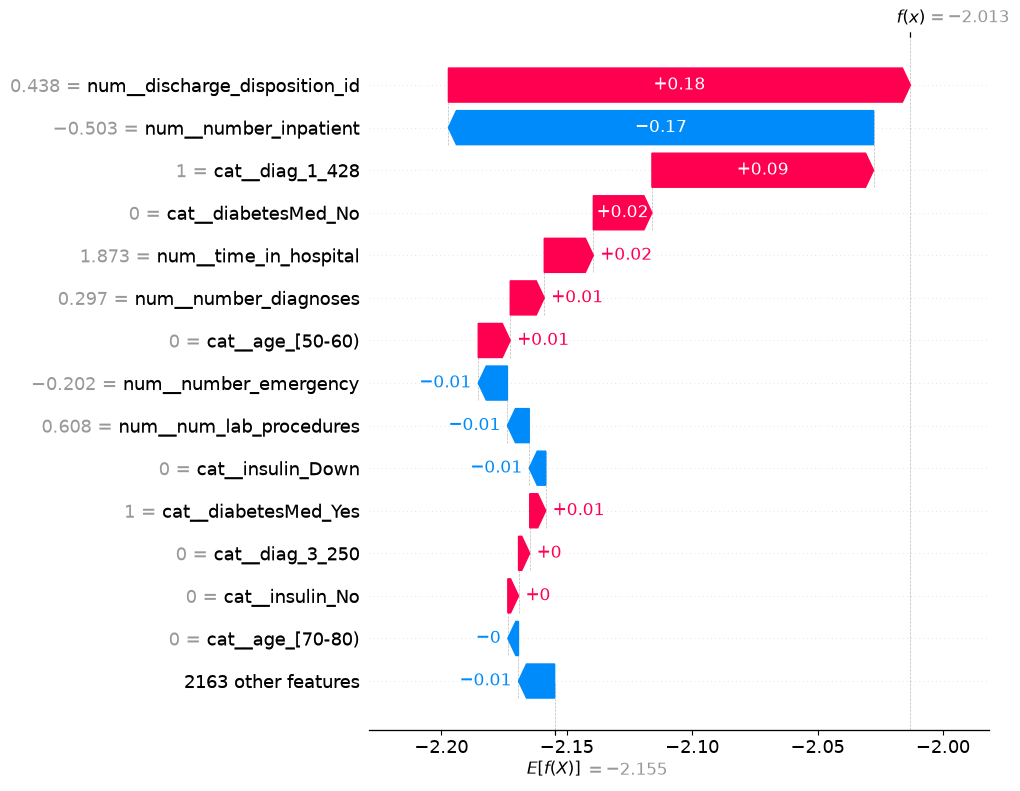

In [18]:

import pandas as pd
import numpy as np
import shap
from scipy import sparse

gb_pipeline = trained_models["Gradient Boosting"]
preprocessor_fitted = gb_pipeline.named_steps["preprocessor"]
classifier = gb_pipeline.named_steps["classifier"]

# Select one test record
X_one = X_test.iloc[[0]]

# Transform the record
X_one_transformed = preprocessor_fitted.transform(X_one)

if sparse.issparse(X_one_transformed):
    X_one_transformed = X_one_transformed.toarray()

X_one_transformed = np.asarray(
    X_one_transformed, dtype=np.float64
)

feature_names = preprocessor_fitted.get_feature_names_out()

# Create a DataFrame with correct transformed feature names
X_one_df = pd.DataFrame(
    X_one_transformed,
    columns=feature_names
)

# Calculate SHAP values
explainer = shap.TreeExplainer(classifier)
shap_exp = explainer(X_one_df)

# Plot with proper feature names
shap.plots.waterfall(shap_exp[0], max_display=15)


In [19]:

# Save the model comparison results
results_df.to_csv(
    "../model_comparison_results.csv",
    index=False
)

print("File saved successfully!")


File saved successfully!


In [20]:

from pathlib import Path
import matplotlib.pyplot as plt

# Save graphs in the main project folder
output_dir = Path("../")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the current feature importance graph
plt.figure()
# Re-create the feature importance chart
top_features = importance_df.head(15).sort_values(
    by="Importance", ascending=True
)

plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Features - Gradient Boosting")
plt.tight_layout()
plt.savefig(
    output_dir / "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("Feature importance graph saved!")

# Save a SHAP summary plot
shap.summary_plot(
    shap_values,
    X_transformed,
    feature_names=feature_names,
    max_display=15,
    show=False
)
plt.savefig(
    output_dir / "shap_summary.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

print("SHAP summary graph saved!")


Feature importance graph saved!
SHAP summary graph saved!


In [ ]:

import joblib

from pathlib import Path

model_path = Path("../hospital_readmission_model.joblib")

joblib.dump(
    trained_models["Gradient Boosting"],
    model_path
)

print("Model saved successfully!")
print(model_path.resolve())


Model saved successfully!
C:\Hospital_Readmission_Project\hospital_readmission_model.joblib


In [1]:

import joblib
from pathlib import Path

model_path = Path("../hospital_readmission_model.joblib")
model = joblib.load(model_path)

preprocessor = model.named_steps["preprocessor"]

print("Model loaded successfully!")
print("\nExpected input columns:")
print(list(preprocessor.feature_names_in_))

print("\nTotal input columns:", len(preprocessor.feature_names_in_))


Model loaded successfully!

Expected input columns:
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'diag_1', 'diag_2', 'diag_3', 'number_diagnoses', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'examide', 'citoglipton', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']

Total input columns: 42


In [2]:

# Compare app inputs with model-required inputs

expected_columns = set(
    model.named_steps["preprocessor"].feature_names_in_
)

app_input_columns = {
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id",
    "admission_source_id", "time_in_hospital",
    "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient",
    "number_emergency", "number_inpatient",
    "number_diagnoses", "diag_1", "diag_2", "diag_3",
    "change", "diabetesMed",
    "metformin", "repaglinide", "nateglinide",
    "chlorpropamide", "glimepiride", "acetohexamide",
    "glipizide", "glyburide", "tolbutamide",
    "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin",
    "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone",
    "metformin-rosiglitazone",
    "metformin-pioglitazone"
}

print("Expected model columns:", len(expected_columns))
print("App input columns:", len(app_input_columns))

print("\nMissing from app:")
print(sorted(expected_columns - app_input_columns))

print("\nExtra app fields:")
print(sorted(app_input_columns - expected_columns))


Expected model columns: 42
App input columns: 42

Missing from app:
[]

Extra app fields:
[]
